In [1]:
# Prerequisites
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (12, 5)

In [2]:
from ponds import PONDS, GAUSS, SIGMOID
import matplotlib.pyplot as plt

## Generating a World Map of Synthetic Data

Using `PONDS` to generate a set of global, synthetic climate data is easy. First, we create an PONDS class object where we specify the number of grid points in latitudinal and longitudinal direction. We also specify how many time steps each time series consists. The PONDS object is initialised with `(lat_size x lon_size)` grid cells, each containing noisy data following a given background trend. <br>

To add one abrupt shift, we simply call the function `PONDS.add_shift()`. This function needs a `shape_method` and a `shift_method` argument which determine the shape of the blob in the grid and the type of abrupt shift in that spatial location. Additionally, the shift method can further be specified by additional `kwargs` arguments in form of a dictionary.

In [3]:
# initialize PONDS object
pd = PONDS(
    lat_size=20,
    lon_size=40,
    time_size=200,
    background_noise=0.01,
    background_trend=0.002,
)

# add random shift
pd.add_shift(
    random_seed=1,
    shape_method=GAUSS,
    shift_method=SIGMOID,
)

# add shift with custom parameters
shift_dict = {
    "shift_steepness": 0.2,
    "shift_magnitude": 0.5,
}
pd.add_shift(
    random_seed=4,
    shape_method=GAUSS,
    shift_method=SIGMOID,
    kwargs=shift_dict,
)

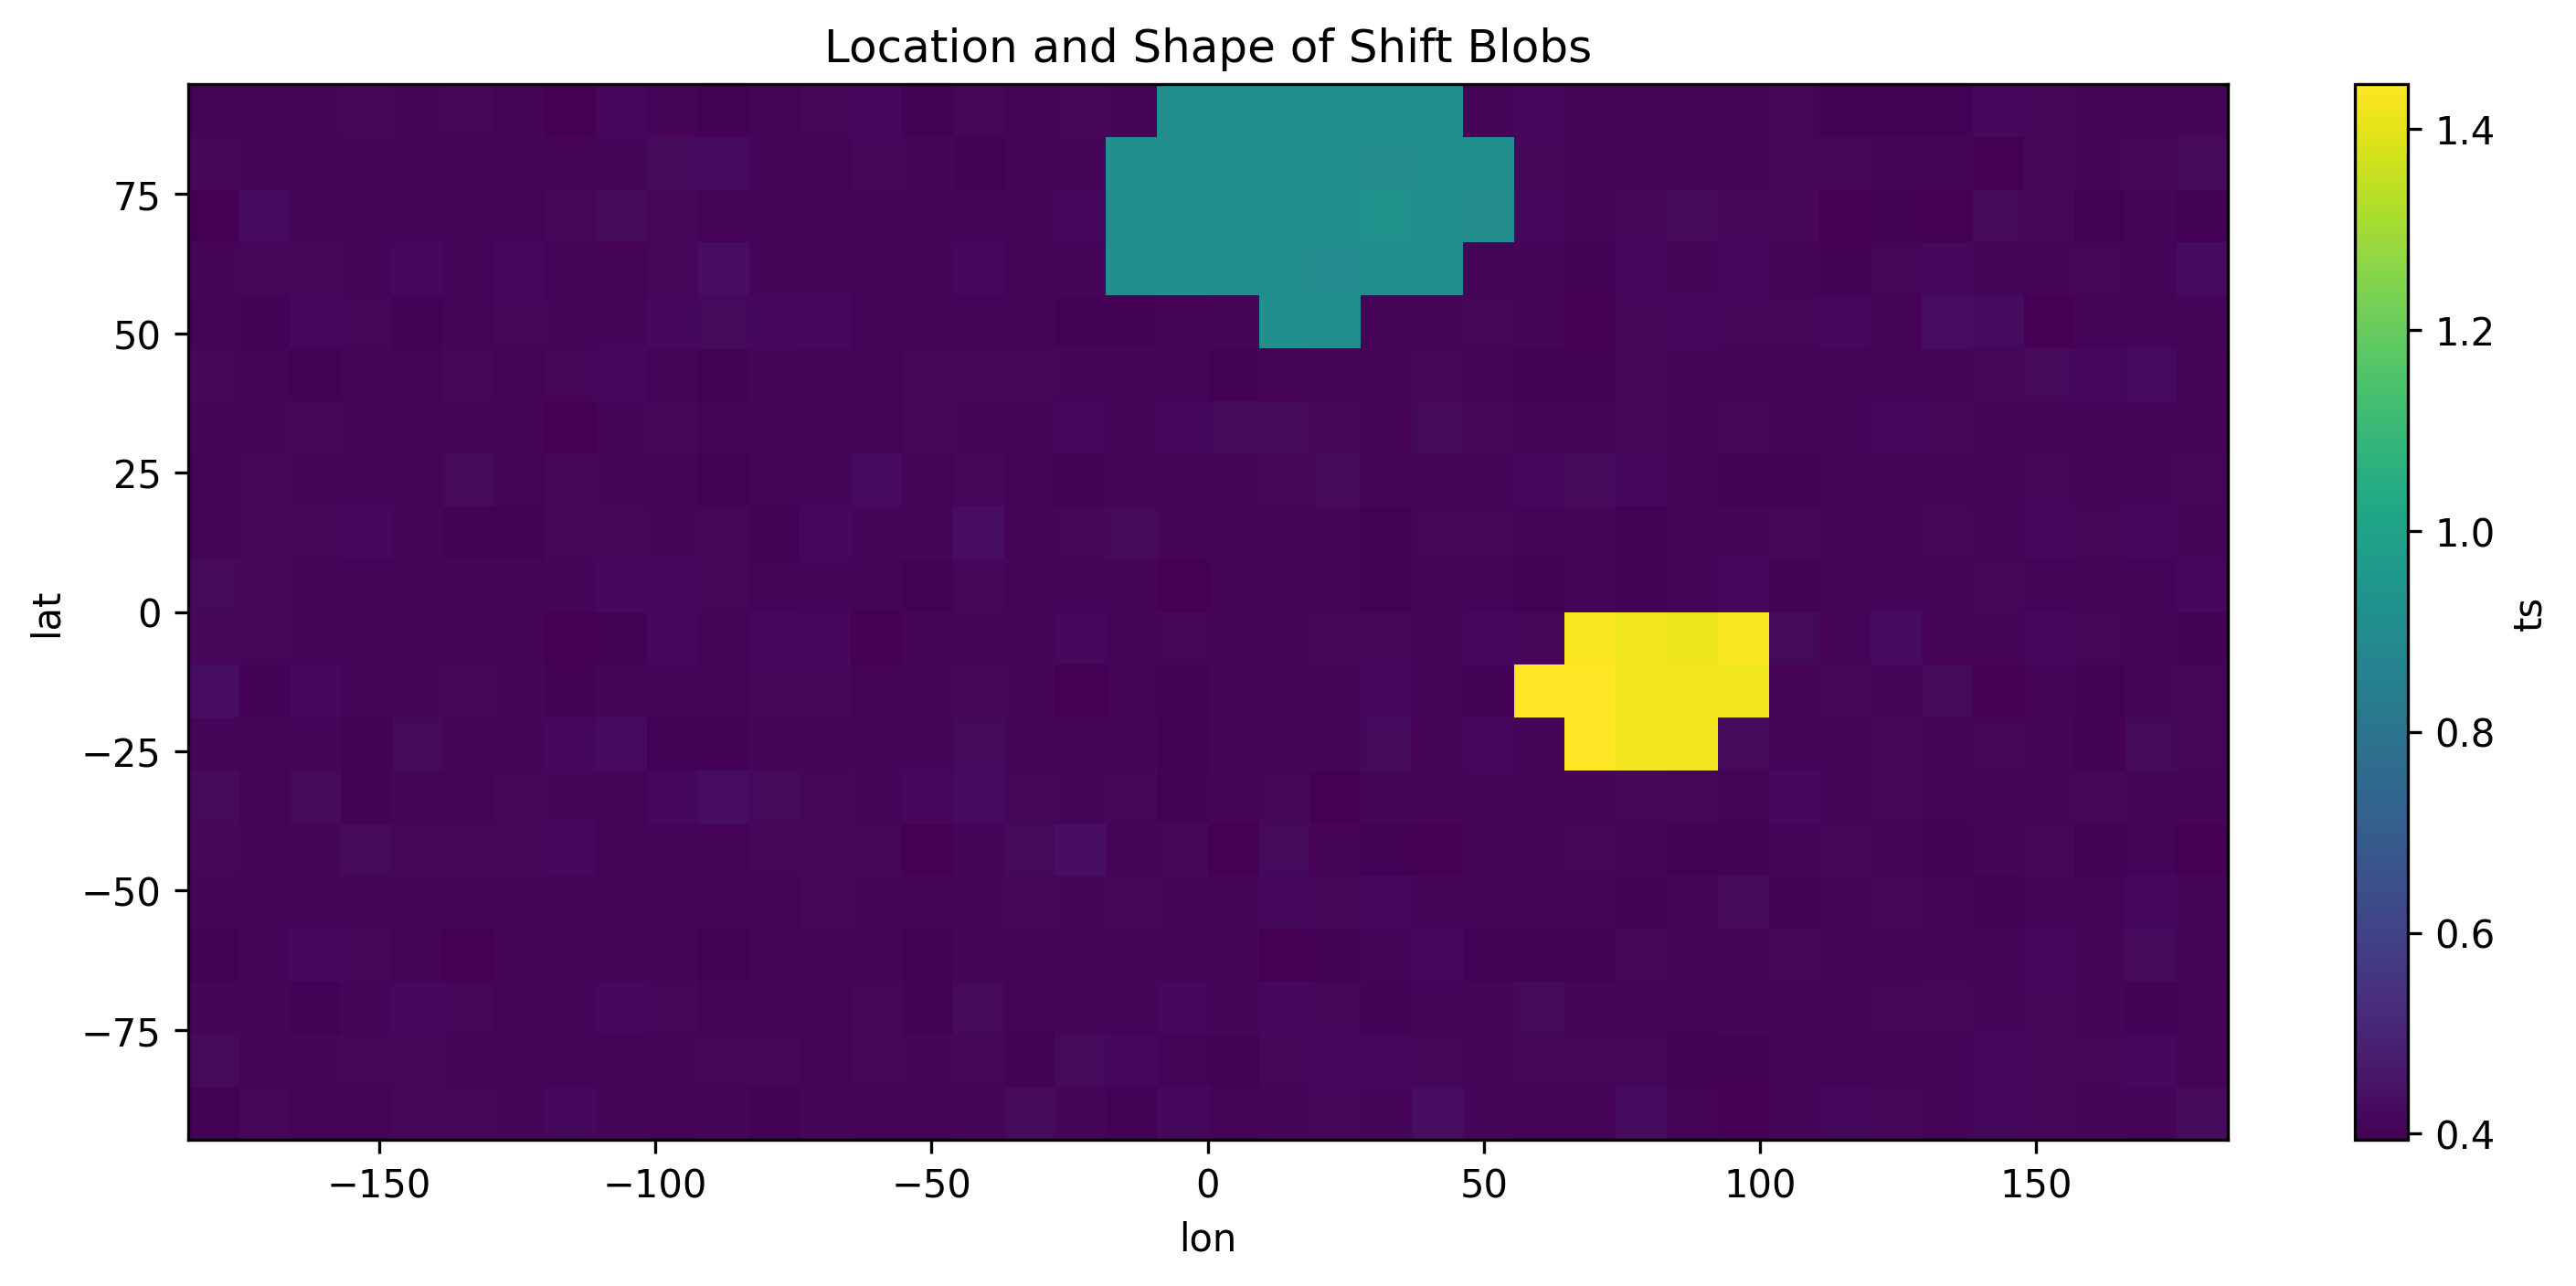

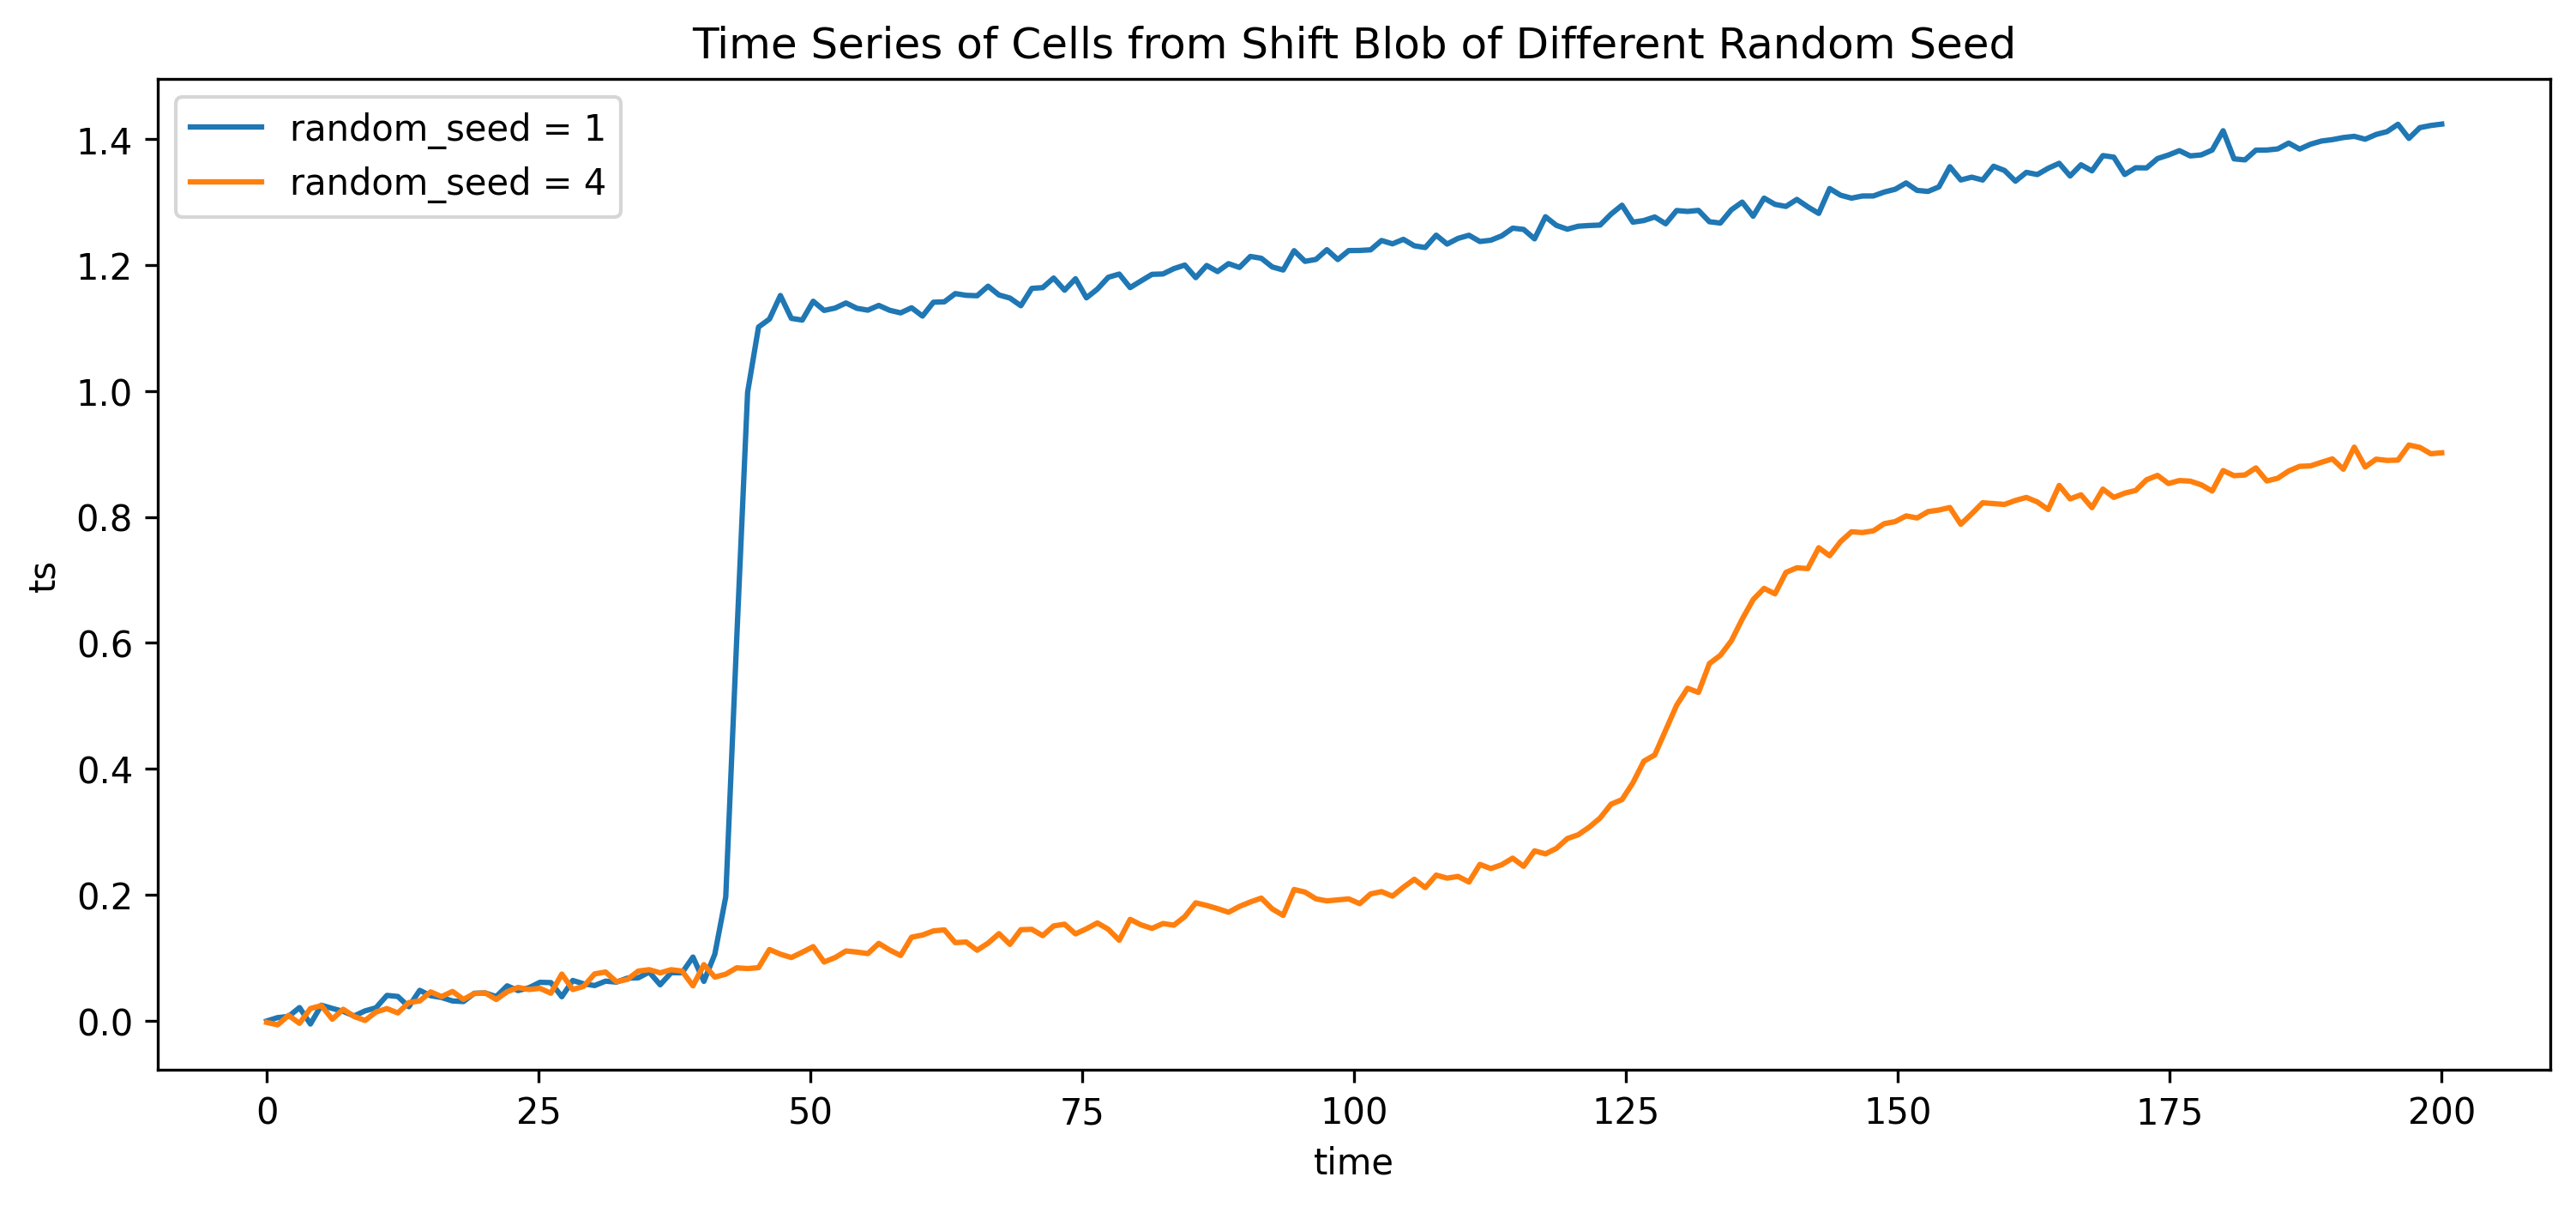

In [4]:
# look at generated time series data
pd.data.ts.max(dim="time").plot()
plt.title("Location and Shape of Shift Blobs")
plt.show()

pd.data.ts.isel(lat=8, lon=28).plot.line(x="time", label="random_seed = 1")
pd.data.ts.isel(lat=17, lon=20).plot.line(x="time", label="random_seed = 4")
plt.legend()
plt.title("Time Series of Cells from Shift Blob of Different Random Seed")
plt.show()

Each added shift is stored as an additional xr.DataArray within the `PONDS.data`. The default name for a shift-cluster is 'c' followed by a running number:

In [16]:
pd.data

<xarray.Dataset> Size: 4kB
Dimensions:  (time: 200, lat: 1, lon: 1)
Coordinates:
  * time     (time) float64 2kB 0.0 1.005 2.01 3.015 ... 197.0 198.0 199.0 200.0
  * lat      (lat) int64 8B 0
  * lon      (lon) int64 8B 0
Data variables:
    ts       (time, lat, lon) float64 2kB 0.01624 -0.004108 ... 0.4281 0.4325
    c1       (time, lat, lon) bool 200B False False False ... False False False
    c2       (time, lat, lon) bool 200B False False False ... False False False

## Using `PONDS` Data with `TOAD`

PONDS is developed in close proximity to TOAD and is therefore highly compatible with this abrupt shift detection package. Here, we want to demonstrate how a use case could look like.


In [5]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from ponds import PONDS, GAUSS, SIGMOID
from toad import TOAD
from toad.shifts_detection.methods import ASDETECT
from sklearn.cluster import HDBSCAN
from toad.visualisation.toad_plotter import PlotConfig

In [11]:
# from ipywidgets import interact
def plot(random_seed=0, n_shifts=1):
    pd = PONDS(
        lat_size=20,
        lon_size=30,
        time_size=200,
        random_seed=random_seed,
        background_noise=0.05,
    )

    for n in range(n_shifts):
        print(f">> Adding Shift {n + 1}/{n_shifts}...")
        pd.add_shift(shape_method=GAUSS, shift_method=SIGMOID)

    data_ds = pd.data.ts.to_dataset(name="ts")
    td = TOAD(data_ds)
    td.compute_shifts("ts", ASDETECT())
    td.compute_clusters(
        "ts",
        HDBSCAN(min_cluster_size=10),
        shifts_filter_func=lambda x: abs(x) > 0.9,
    )

    plt.rcParams["figure.dpi"] = 300

    plotter = td.plotter(
        PlotConfig(
            map_frame=False,
            grid_labels=False,
        )
    )

    plotter.cluster_overview(
        "ts",
        range(10),
        cmap="tab10",
        timeseries_kwargs={},
        map_kwargs={"add_contour": False},
        figsize=(16, 5),
    )

    # Plot true shift locations
    # - Create a list of da_max for all relevant variables
    da_max_list = []
    for name, da in pd.data.data_vars.items():
        if name.startswith("c"):
            da_max = da.max(dim="time")
            da_max_list.append(da_max)
    # - Combine into a single DataArray by taking maximum across them
    combined_da_max = xr.concat(da_max_list, dim="new_dim").max(dim="new_dim")
    # - Plot the combined result
    fig, ax = plotter.map(figsize=(16, 4))
    combined_da_max.plot(
        ax=ax,
        cmap="Blues",
        vmin=0.1,
        vmax=1,
        add_colorbar=False,
    )
    combined_da_max.plot.contour(
        ax=ax, add_colorbar=False, colors=["blue"], vmin=0.1, vmax=1, levels=1
    )

    # Create custom legend
    legend_handles = [
        mpatches.Patch(color="blue", label="SIGMOID"),
    ]
    ax.legend(handles=legend_handles, loc="lower left")
    ax.set_title("True shift locations")

    # plot cluster timeseries
    fig, axs = plt.subplots(2, 1, figsize=(16, 4))
    plotter.cluster_timeseries("ts", td.get_cluster_ids("ts"), ax=axs[0])

    # plot data timeseries
    td.data.ts.toad.to_timeseries().plot.line(
        x="time", add_legend=False, color="k", alpha=0.1, ax=axs[1]
    )
    axs[0].set_title(f"Cluster {td.get_cluster_ids('ts')} timeseries")
    axs[1].set_title("All data timeseries")
    fig.tight_layout()

>> Adding Shift 1/3...
>> Adding Shift 2/3...
>> Adding Shift 3/3...


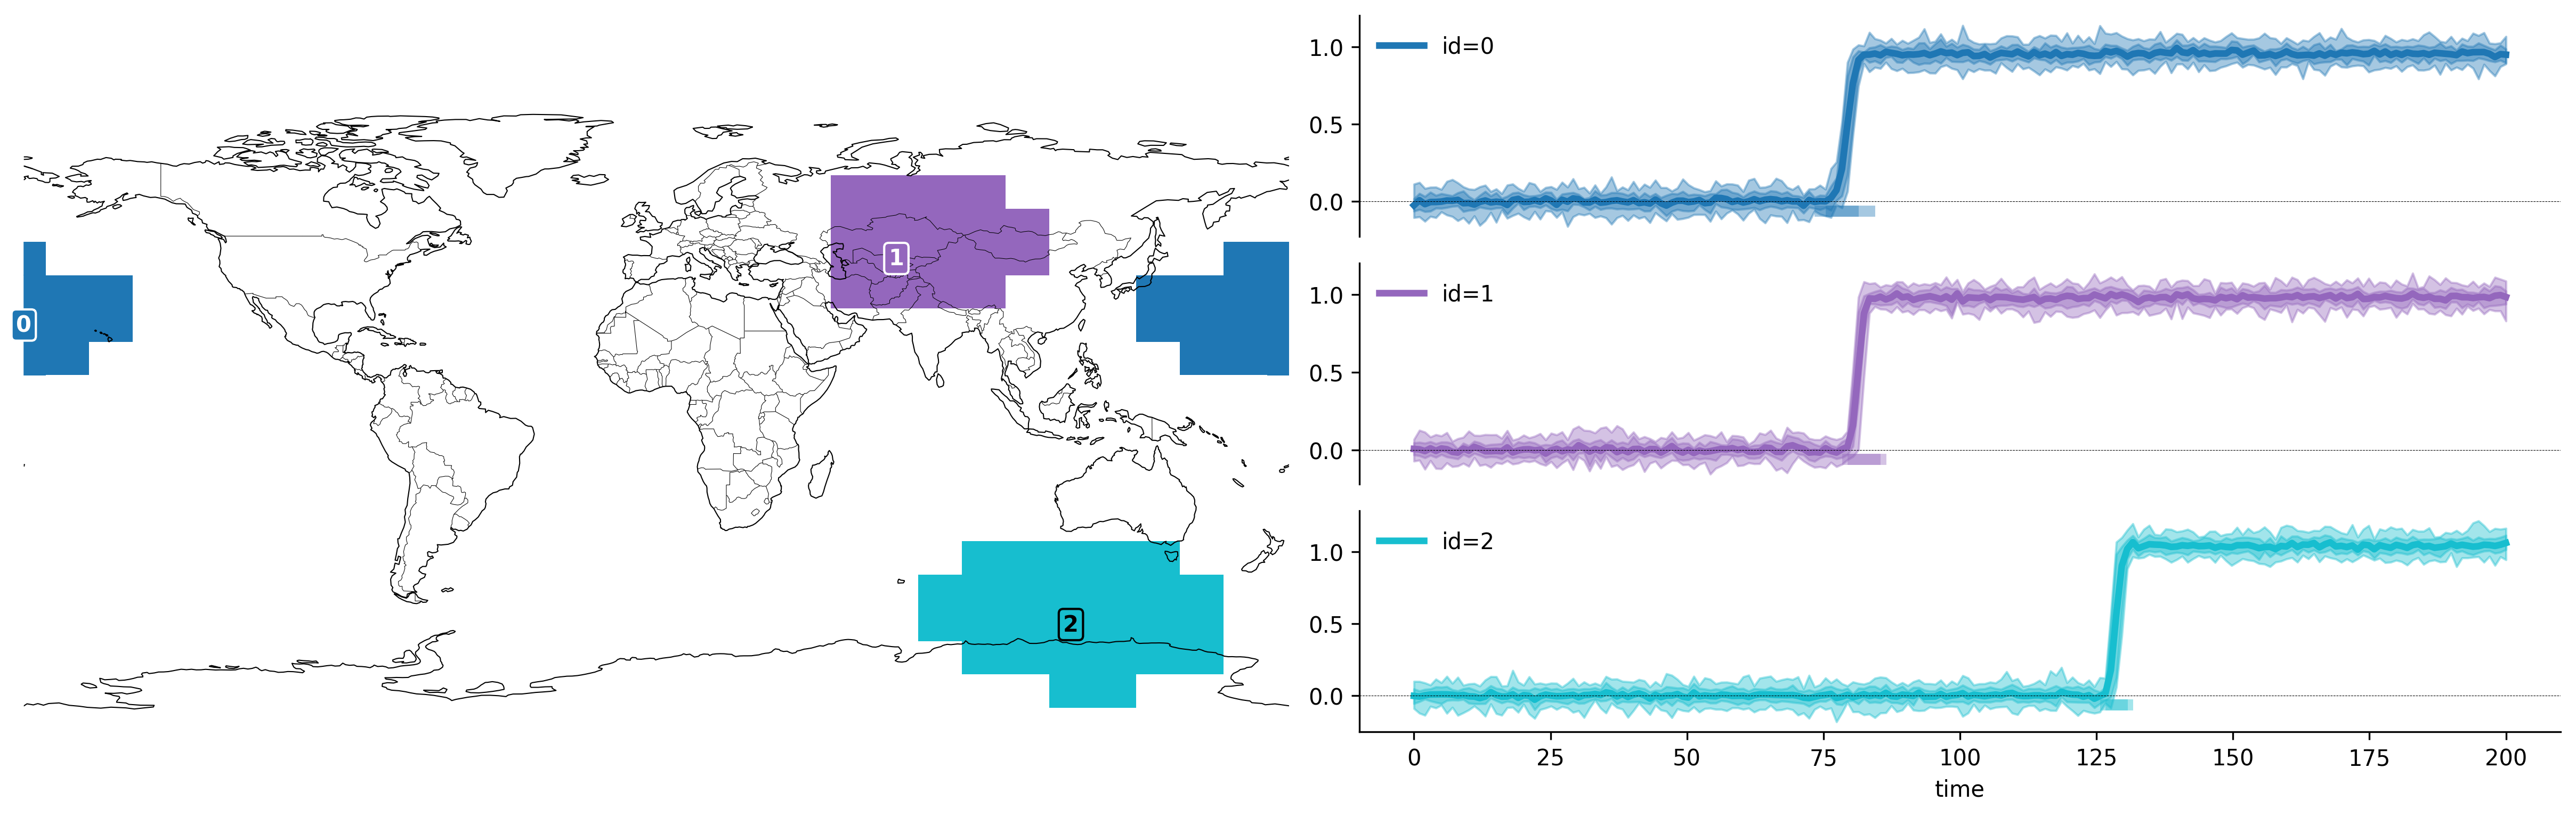

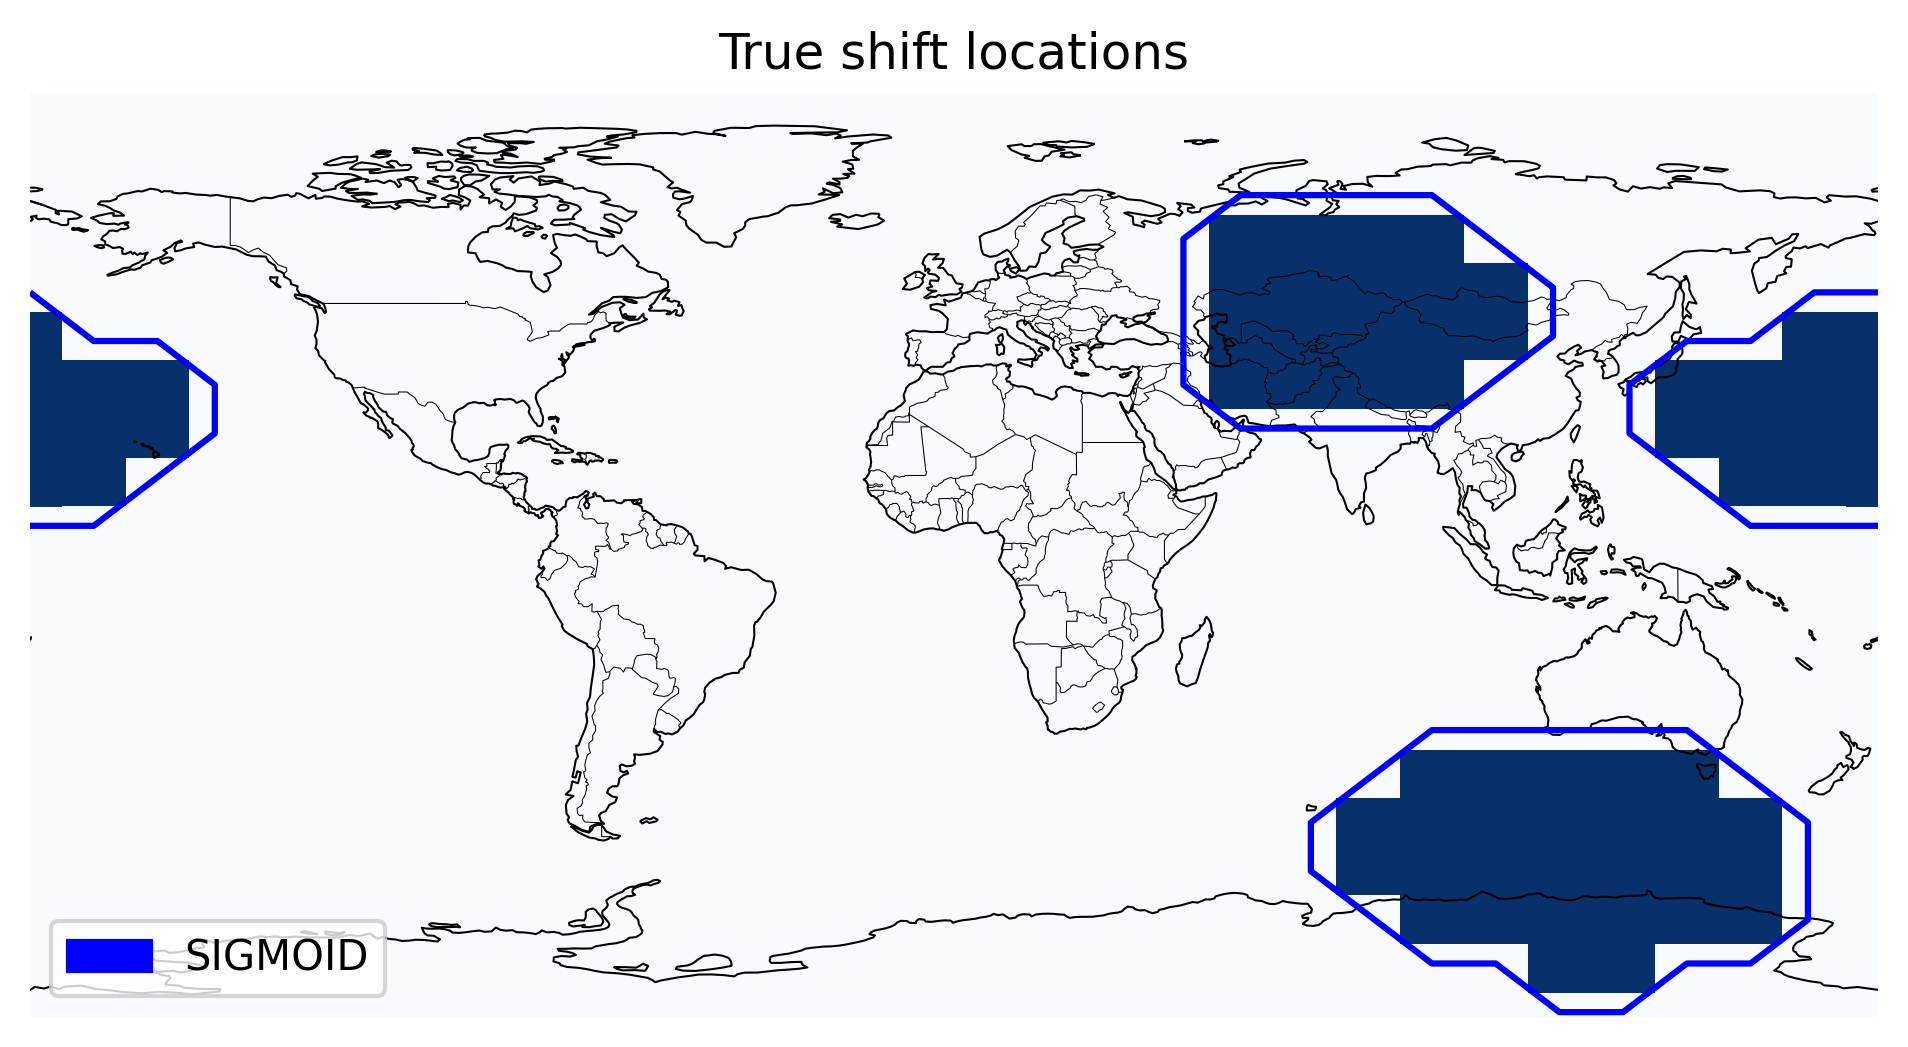

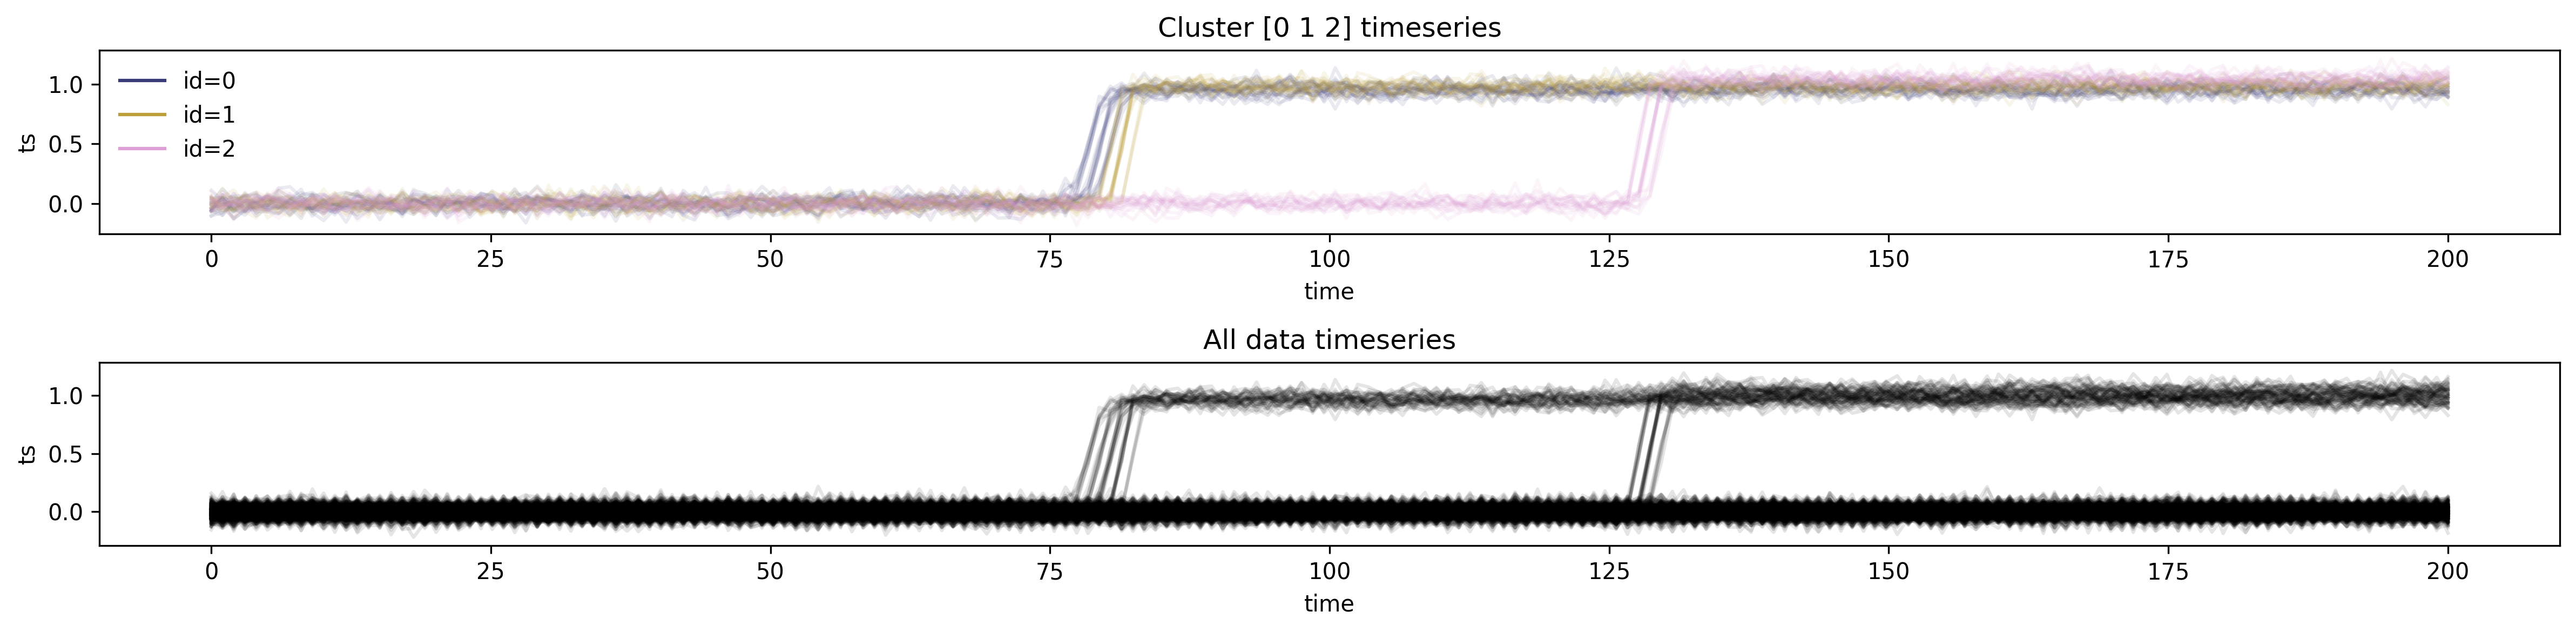

In [12]:
plot(random_seed=2, n_shifts=3)

## Creating a Single Time Series

Another advantage of `PONDS` is that it can also be used to generate single time series. For that matter, we use the `shape_method = SINGLE`. This method is special compared to other shape methods. When calling it **for the first time** with a given PONDS object that is not of the shape `(lat_size x lon_size) = (1 x 1)`, it **erases all previously generated content** in the time series of the class object and generates a new grid, containing only a single time series. This time series can be modified the same way as before by adding abrupt shifts.

In [13]:
from ponds import PONDS, SINGLE, SIGMOID
import matplotlib.pyplot as plt

In [14]:
pd = PONDS(
    time_size=200,
    background_noise=0.01,
    background_trend=0.002,
)

# first time calling SINGLE shape method:
# this will erase all previous time series and rehsape the ponds object grid
# -> will trigger a UserWarning
pd.add_shift(
    random_seed=1,
    shape_method=SINGLE,
    shift_method=SIGMOID,
)

# second time calling SINGLE shape method:
# previous time series (including the shift) is conserved and the new shift is added
shift_dict = {"shift_magnitude": -1}
pd.add_shift(
    random_seed=2,
    shape_method=SINGLE,
    shift_method=SIGMOID,
    kwargs=shift_dict,
)

/home/lukasro/Documents/TIPMIP/ponds/ponds/blobgen.py:110: UserWarning: Shape method SINGLE used on a non-single ponds object.This step erases all time series and starts the ponds object over.
  warnings.warn(


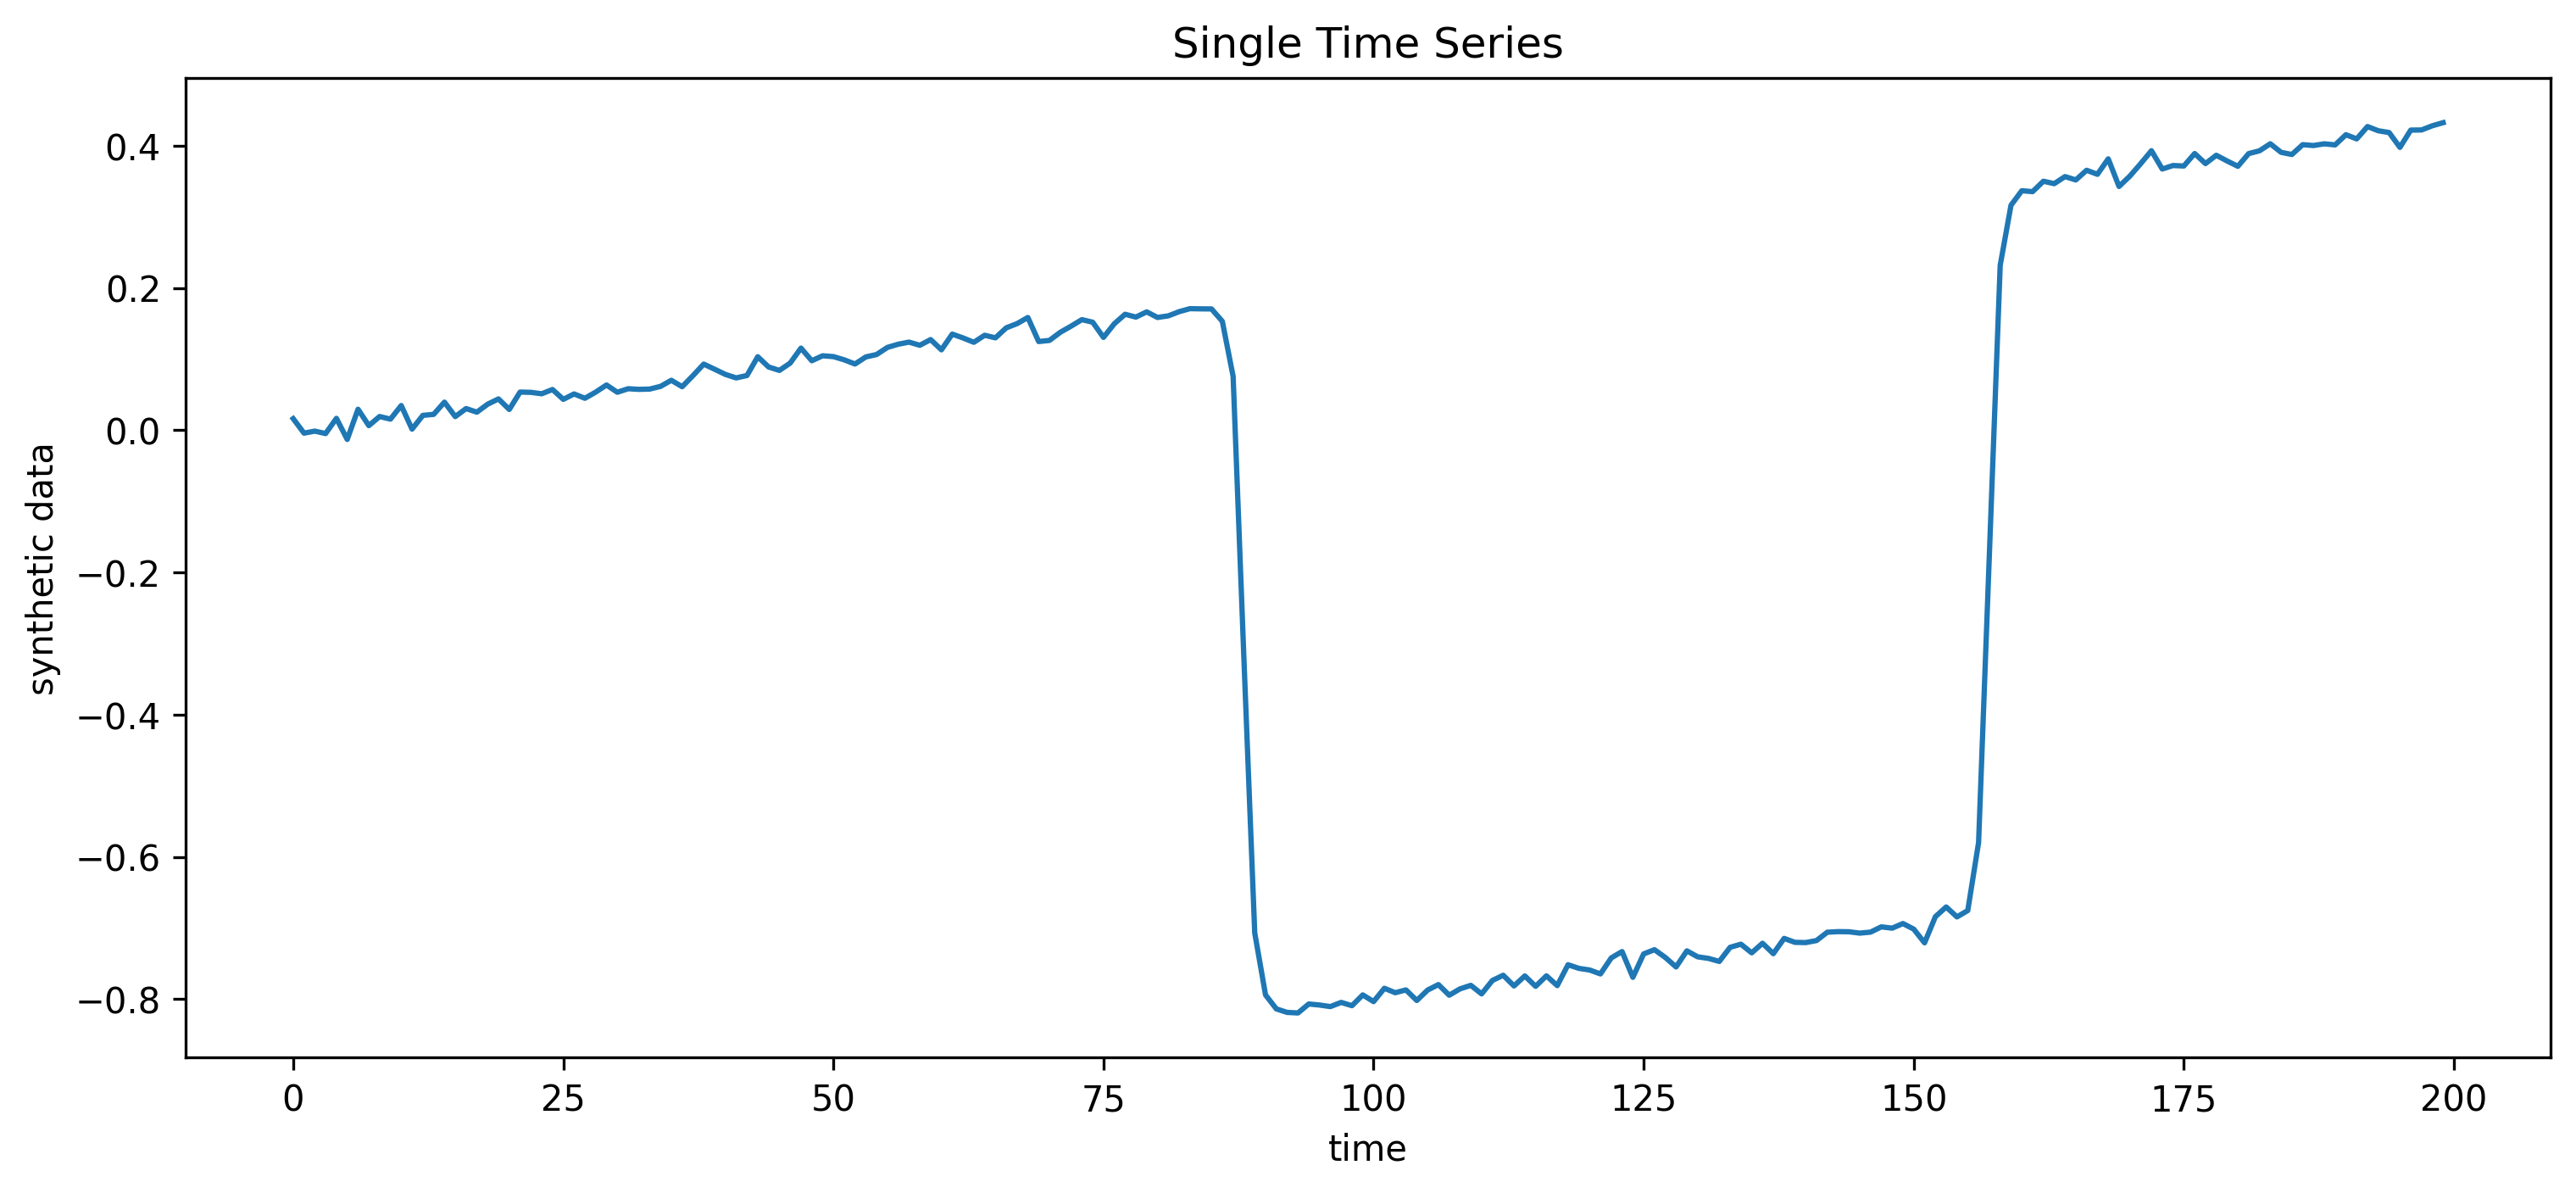

In [15]:
# get the single time series
ts = pd.get_ts(single=True)

# plot the single time series
plt.plot(ts)

plt.title("Single Time Series")
plt.xlabel("time")
plt.ylabel("synthetic data")
plt.show()